# Import 

In [1]:
import numpy as np
import random
import csv
from collections import Counter
import os
import matplotlib.pyplot as plt

# Data Loarding

In [2]:
ratings_path = (
    "/kaggle/input/datasets/alimisaragankou/ml-32m/ratings.csv"
)

movies_path = (
    "/kaggle/input/datasets/alimisaragankou/ml-32m/movies.csv"
)

# Practical 1 with EDA

**EDA over 32M**

In [3]:
# Reading of movie's table for EDA

movie_titles = {}
movie_genres = {}

with open(movies_path, "r", encoding="utf-8") as file:
    reader = csv.reader(file)
    next(reader)

    for row in reader:
        movie_id = row[0]
        title = row[1]
        genres = row[2].split("|")

        movie_titles[movie_id] = title
        movie_genres[movie_id] = genres

In [4]:
print("Number of movies:", len(movie_titles))
print(movie_titles["1"])
print(movie_genres["1"])

Number of movies: 87585
Toy Story (1995)
['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy']


In [5]:
# Initialisation
rating_counts = Counter()  # Dict of each rating and its frequency
user_counts = Counter()  # dict of each user and their degree
item_counts = Counter()  # Dict of each item and its degree

item_rating_sum = Counter()  # dict of each item and the sum of its ratings
genre_rating_count = Counter()  # Dict of each genre and its number of ratings
genre_rating_sum = Counter()  # Dict of each genre and the sum of its ratings

sum_ratings = 0  # Sum of ratings
sum_squared_ratings = 0  # Sum of squared ratings
n_ratings = 0  # Number of ratings

# Reading of rating's table
with open(ratings_path, "r") as file:
    reader = csv.reader(file)
    next(reader)

    for row in reader:
        user = row[0]
        item = row[1]
        rating = float(row[2])

        n_ratings += 1
        sum_ratings += rating
        sum_squared_ratings += rating ** 2

        # Rating distribution
        rating_counts[rating] += 1

        # Number of ratings by user and item
        user_counts[user] += 1
        item_counts[item] += 1

        # Sum of ratings by item
        item_rating_sum[item] += rating

        # Statistics by genre
        if item in movie_genres:
            for genre in movie_genres[item]:
                genre_rating_count[genre] += 1
                genre_rating_sum[genre] += rating

In [6]:
n_users = len(user_counts)
n_items = len(item_counts)

mean_rating = sum_ratings / n_ratings

variance_rating = (
    sum_squared_ratings / n_ratings
    - mean_rating ** 2
)


print(f"Number of ratings: {n_ratings}")
print(f"Number of users: {n_users}")
print(f"Number of movies: {n_items}")
print(f"Mean rating: {mean_rating:.3f}")
print(f"Mean rating: {variance_rating:.3f}")

Number of ratings: 32000204
Number of users: 200948
Number of movies: 84432
Mean rating: 3.540
Mean rating: 1.121


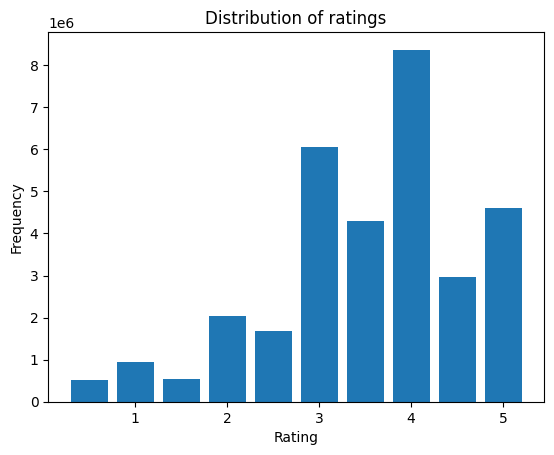

In [7]:
# Distribution of rating

ratings = sorted(rating_counts.keys())
counts = [rating_counts[rating] for rating in ratings]

plt.bar(ratings, counts, width=0.4)
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Distribution of ratings")

plt.savefig(
    "/kaggle/working/distribution_ratings.pdf",
    bbox_inches="tight"
)

plt.show()

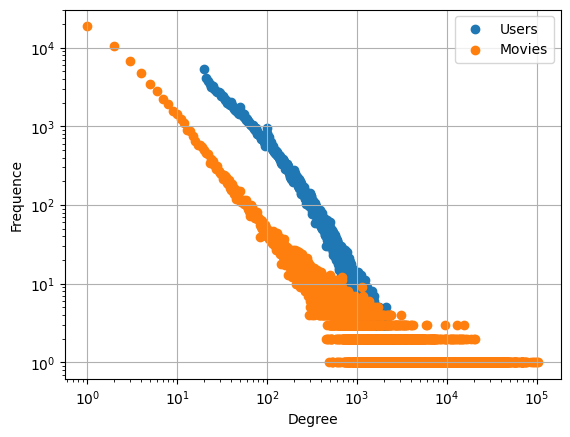

In [8]:
# Power law

user_degrees = np.array(list(user_counts.values()))
item_degrees = np.array(list(item_counts.values()))

user_degree_values, user_degree_counts = np.unique(
    user_degrees,
    return_counts=True
)

item_degree_values, item_degree_counts = np.unique(
    item_degrees,
    return_counts=True
)


plt.scatter(x=user_degree_values, y = user_degree_counts, label = "Users")
plt.scatter(x=item_degree_values, y = item_degree_counts, label = "Movies")
plt.legend(loc="upper right")
plt.xlabel("Degree")
plt.ylabel("Frequence")
plt.xscale("log")
plt.yscale("log")
plt.grid(True)
plt.savefig("power_law.pdf", bbox_inches="tight")
plt.show()

In [9]:
# Most movies rated
most_rated_movies = item_counts.most_common(10)
most_rated_movies

[('318', 102929),
 ('356', 100296),
 ('296', 98409),
 ('2571', 93808),
 ('593', 90330),
 ('260', 85010),
 ('2959', 77332),
 ('480', 75233),
 ('527', 73849),
 ('4993', 73122)]

In [10]:
print("Top 10 most rated movies\n")

for movie_id, count in most_rated_movies:
    mean = item_rating_sum[movie_id] / count

    print(
        f"{movie_titles[movie_id]}: "
        f"{count} ratings, "
        f"mean rating = {mean:.2f}"
    )

Top 10 most rated movies

Shawshank Redemption, The (1994): 102929 ratings, mean rating = 4.40
Forrest Gump (1994): 100296 ratings, mean rating = 4.05
Pulp Fiction (1994): 98409 ratings, mean rating = 4.20
Matrix, The (1999): 93808 ratings, mean rating = 4.16
Silence of the Lambs, The (1991): 90330 ratings, mean rating = 4.15
Star Wars: Episode IV - A New Hope (1977): 85010 ratings, mean rating = 4.10
Fight Club (1999): 77332 ratings, mean rating = 4.23
Jurassic Park (1993): 75233 ratings, mean rating = 3.70
Schindler's List (1993): 73849 ratings, mean rating = 4.24
Lord of the Rings: The Fellowship of the Ring, The (2001): 73122 ratings, mean rating = 4.09


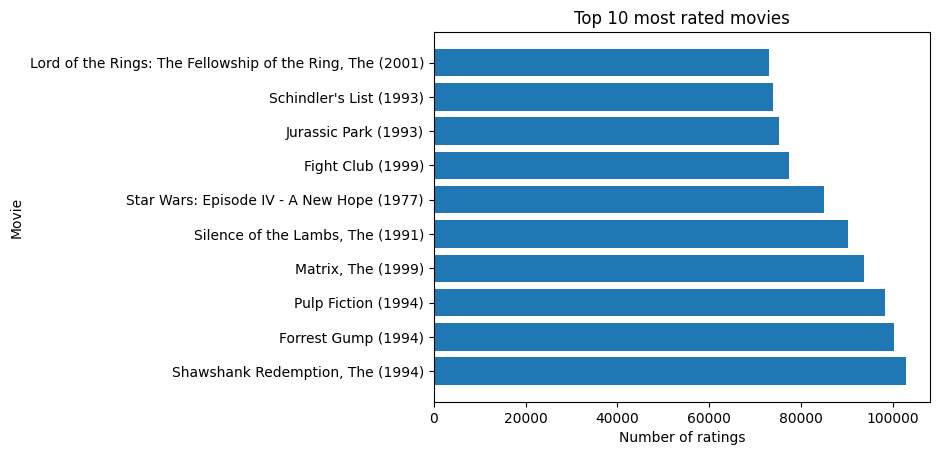

In [11]:
movie_names = [
    movie_titles[movie_id]
    for movie_id, count in most_rated_movies
]

movie_counts = [
    count
    for movie_id, count in most_rated_movies
]

plt.barh(
    movie_names,
    movie_counts
)
plt.xlabel("Number of ratings")
plt.ylabel("Movie")
plt.title("Top 10 most rated movies")

plt.savefig(
    "/kaggle/working/most_rated_movies.pdf",
    bbox_inches="tight"
)

plt.show()

In [12]:
genre_counts = {
    genre: count
    for genre, count in genre_rating_count.items()
    if genre != "(no genres listed)"
}

sorted_genres = sorted(
    genre_counts.items(),
    key=lambda x: x[1],
    reverse=True
)

genres = [
    genre
    for genre, count in sorted_genres
]

counts = [
    count
    for genre, count in sorted_genres
]

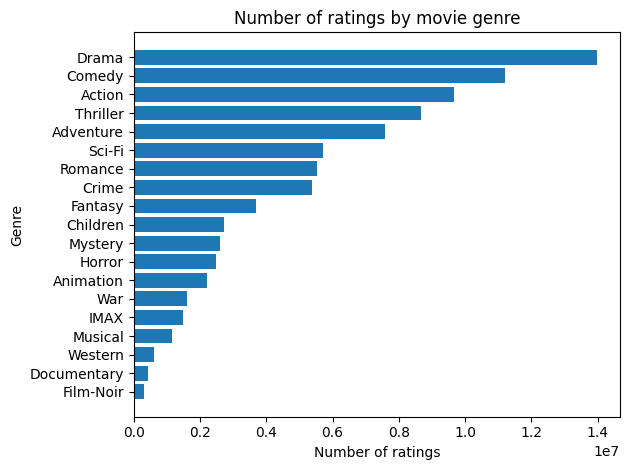

In [13]:
plt.barh(
    genres,
    counts
)
plt.gca().invert_yaxis()
plt.xlabel("Number of ratings")
plt.ylabel("Genre")
plt.title("Number of ratings by movie genre")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/ratings_by_genre.pdf",
    bbox_inches="tight"
)

plt.show()

In [14]:
genre_mean_ratings = {}

for genre in genre_rating_count:
    if genre != "(no genres listed)":
        genre_mean_ratings[genre] = (
            genre_rating_sum[genre]
            / genre_rating_count[genre]
        )
        
sorted_genre_means = sorted(
    genre_mean_ratings.items(),
    key=lambda x: x[1],
    reverse=True
)

genres = [
    genre
    for genre, mean in sorted_genre_means
]

means = [
    mean
    for genre, mean in sorted_genre_means
]

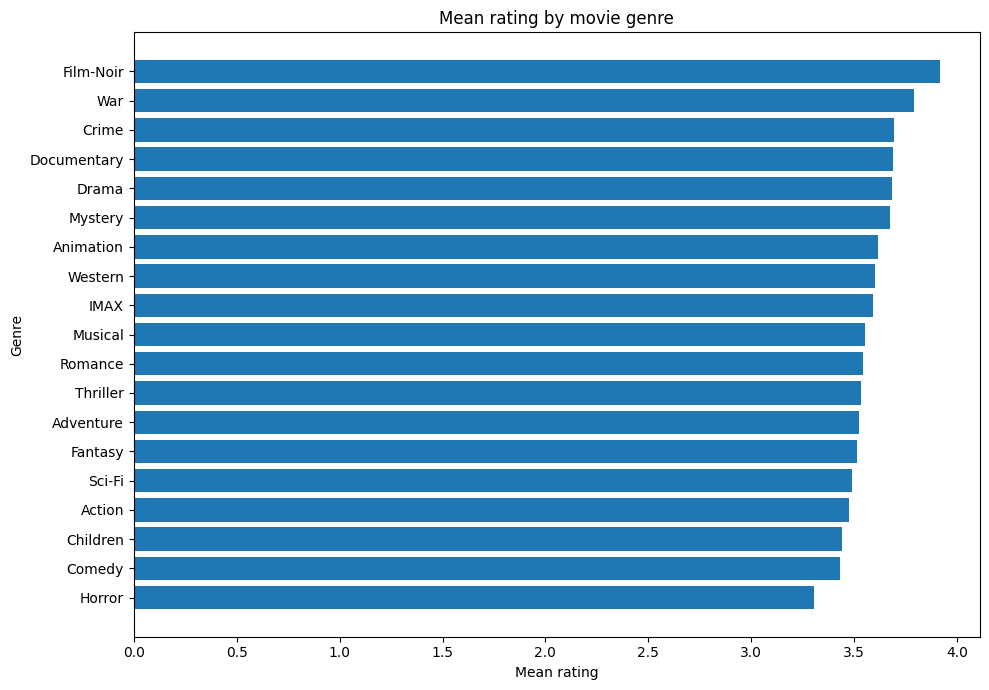

In [15]:
plt.figure(figsize=(10, 7))

plt.barh(
    genres,
    means
)
plt.gca().invert_yaxis()
plt.xlabel("Mean rating")
plt.ylabel("Genre")
plt.title("Mean rating by movie genre")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/mean_rating_by_genre.pdf",
    bbox_inches="tight"
)

plt.show()

## Indexation

Indexation over 100k

In [16]:
user_to_index = {} # dictionary of the name of user as key and it index as value
index_to_user = [] # list of index's user

item_to_index = {} #  dictionary of the name of item (movie) as key and it index as value
index_to_item = [] # list of index's item

data_by_user = []  # data of user
data_by_item = [] # data of item (movie)


# Reading of data 
with open(ratings_path, 'r') as file:
    reader = csv.reader(file)
    next(reader)
    for i, row in enumerate(reader):
        if i > 100000:
            break
        user = row[0]
        movie = row[1]
        rate = float(row[2])
        
        if user not in user_to_index:
            user_to_index[user] =len(index_to_user)
            index_to_user.append(user)
            data_by_user.append([])
        if movie not in item_to_index:
            item_to_index[movie] = len(index_to_item)
            index_to_item.append(movie)
            data_by_item.append([])
        # appending of movie and rate to user
        data_by_user[user_to_index[user]].append((item_to_index[movie], rate))
        # appending of user and rate to movie
        data_by_item[item_to_index[movie]].append((user_to_index[user], rate))

# Practical 2

### Split 

In [17]:
# Initialisation of train's and test's data
data_by_user_train = [] 
data_by_user_test = []  

data_by_item_train = [] 
data_by_item_test = [] 

split_rate = 0.8  # size of trining data

for user_index, user in enumerate(data_by_user):
    data_by_user_train.append([])
    data_by_user_test.append([])
    train_size =(len(user)*split_rate)
    random.shuffle(user)
    for i, rate in enumerate(user):
        if i <=train_size :
            data_by_user_train[user_index].append(rate)
        else:
            data_by_user_test[user_index].append(rate)


for item_index, item in enumerate(data_by_item):
    data_by_item_train.append([])
    data_by_item_test.append([])
    train_size = int(len(item)*0.8)
    random.shuffle(item)
    for i, rate in enumerate(item):
        if i <=train_size :
            data_by_item_train[item_index].append(rate)
        else:
            data_by_item_test[item_index].append(rate)

In [18]:
len(data_by_user_train[0])

113

In [19]:
len(data_by_user_test[0])

28

### ALS Model for biases only

In [20]:
# Initialisation of user and item biases 
users_bias = np.zeros(len(data_by_user_train)) 
items_bias = np.zeros(len(data_by_item_train))

# Initialisation of rmse and loss
rmse_train = []
rmse_test = []
loss_train = []

# Parameters of regularisation
lamb = 0.3
gamma = 0.2



# RMSE function
def rmse_function(data, user_bias, item_bias):
    """
    Compute the RMSE with biases.

    Parameters
    ----------
    data : list
        Ratings grouped by user as (item_index, rating) pairs.
    user_bias : np.ndarray
        Bias values associated with users.
    item_bias : np.ndarray
        Bias values associated with items.

    Returns
    -------
    float
        RMSE of the model predictions.
    """

    sum_square_error = 0
    n_ratings = 0

    for u, user_ratings in enumerate(data):
        for i, rating in user_ratings:
            prediction = user_bias[u] + item_bias[i]
            sum_square_error += (rating - prediction) ** 2
            n_ratings += 1

    return (sum_square_error / n_ratings) ** 0.5


# Loss function
def loss_function(data, user_bias, item_bias, lamda, gamma):
    """
    Compute the loss function of the model.

    Parameters
    ----------
    data : list
        Ratings grouped by user as (item_index, rating) pairs.
    user_bias : np.ndarray
        Bias values associated with users.
    item_bias : np.ndarray
        Bias values associated with items.
    lamda : float
        Weight of the squared error term.
    gamma : float
        Regularization parameter for user and item biases.

    Returns
    -------
    float
        Value of the loss function.
    """

    squared_error = 0

    for u, user_ratings in enumerate(data):
        for i, rating in user_ratings:
            prediction = user_bias[u] + item_bias[i]
            squared_error += (rating - prediction) ** 2

    bias_penalty = np.sum(user_bias ** 2) + np.sum(item_bias ** 2)

    loss = (lamda / 2) * squared_error + (gamma / 2) * bias_penalty
    

    return loss

for iteration in range(40):
    
    for m in range(len(data_by_user_train)):
        bias = 0
        item_counter = 0
        for i, r in data_by_user_train[m]: 
            bias += lamb*(r - items_bias[i])
            item_counter+=1
        bias = bias/(lamb*item_counter + gamma)
        users_bias[m] = bias
        
    for m in range(len(data_by_item_train)):
        bias = 0
        item_counter = 0
        for i, r in data_by_item_train[m]: 
            bias += lamb*(r - users_bias[i])
            item_counter+=1
        bias = bias/(lamb*item_counter + gamma)
        items_bias[m] = bias
        
    rmse_train.append(rmse_function(data_by_user_train, users_bias, items_bias))
    rmse_test.append(rmse_function(data_by_user_test, users_bias, items_bias))
    loss_train.append(loss_function(data_by_user_train, users_bias, items_bias, lamb, gamma))

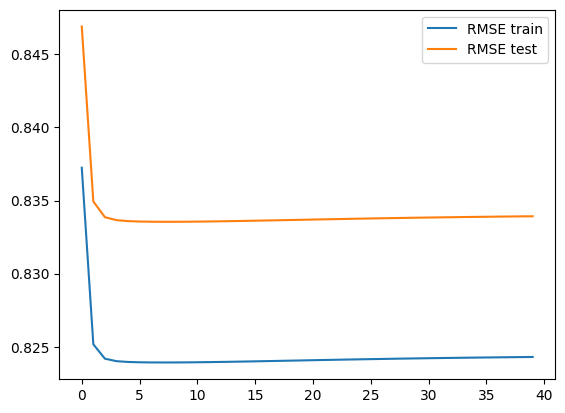

In [21]:
# plots of train's and test's rmse

plt.plot(rmse_train, label="RMSE train")
plt.plot(rmse_test, label = "RMSE test")
plt.legend()
plt.savefig("rmse_biases.pdf", bbox_inches="tight")
plt.show()

In [22]:
min(rmse_train)

np.float64(0.823926073670741)

In [23]:
min(rmse_test)

np.float64(0.8335478068645205)

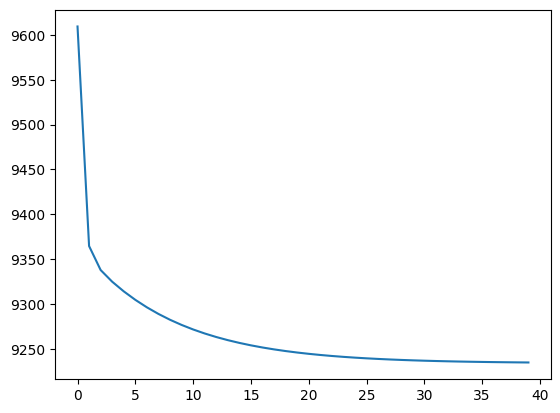

In [24]:
# Plot of loss function

plt.plot(loss_train)
plt.savefig("loss_biases.pdf", bbox_inches="tight")
plt.show()

In [25]:
min(loss_train)

np.float64(9234.631779927084)

# Pratical 3

###  ALS model with biases and user-item factor's latent

In [26]:
# RMSE function
def rmse_function_2(data, user_bias, item_bias, U, V):
    """
    Compute the Root Mean Squared Error (RMSE) with biases and latent factors of users and items.

    Parameters
    ----------
    data : list
        Ratings grouped by user as (item_index, rating) pairs.
    user_bias : np.ndarray
        Bias values associated with users.
    item_bias : np.ndarray
        Bias values associated with items.
    U : np.ndarray
        Matrix of user latent factors.
    V : np.ndarray
        Matrix of item latent factors.

    Returns
    -------
    float
        Root Mean Squared Error of the model predictions.
    """
    # Initialisation
    sum_square_error = 0
    n_ratings = 0

    for u, user_ratings in enumerate(data):
        for i, rating in user_ratings:
            prediction = np.dot(U[u], V[i]) + user_bias[u] + item_bias[i]
            sum_square_error += (rating - prediction) ** 2
            n_ratings += 1

    return (sum_square_error / n_ratings) ** 0.5


# loss function with regularisation term
def loss_function_2(data, user_bias, item_bias, lambda_, gamma, tau, U, V):
    """
    Compute the loss function with biases and latent factors of user and item.

    Parameters
    ----------
    data : list
        Ratings grouped by user as (item_index, rating) pairs.
    user_bias : np.ndarray
        Bias values associated with users.
    item_bias : np.ndarray
        Bias values associated with items.
    lambda_ : float
        Weight of the squared error term.
    gamma : float
        Regularization parameter for user and item biases.
    tau : float
        Regularization parameter for latent factors.
    U : np.ndarray
        Matrix of user latent factors.
    V : np.ndarray
        Matrix of item latent factors.

    Returns
    -------
    float
        Value of the regularized loss function.
    """
    
    squared_error = 0  # Initialisation of square error
    
    for u, user_ratings in enumerate(data):
        for i, rating in user_ratings:
            prediction = np.dot(U[u], V[i]) + user_bias[u] + item_bias[i]
            squared_error += (rating - prediction) ** 2

    bias_penalty = np.sum(user_bias ** 2) + np.sum(item_bias ** 2)

    factor_penalty = np.sum(U ** 2) + np.sum(V ** 2)
    
    loss = (lambda_ / 2) * squared_error + (gamma / 2) * bias_penalty + (tau / 2) * factor_penalty

    return loss

In [27]:
lamda = 0.1
gamma = 0.1
tau = 0.1
k = 8

# Initialisation of user and item biases
users_bias_2 = np.zeros(len(data_by_user_train))
items_bias_2 = np.zeros(len(data_by_item_train))

# Initialisation of user and item latent factors
U = np.random.normal(scale=0.1, size=(len(data_by_user_train), k))

V = np.random.normal(scale=0.1,size=(len(data_by_item_train), k))

# Initialisation of evaluation metrics
rmse_train_2 = []
rmse_test_2 = []
loss_train_2 = []


for iteration in range(35):

    # Updating of user biases and latent factors
    for u in range(len(data_by_user_train)):
        bias = 0
        n_ratings = 0

        for i, rating in data_by_user_train[u]:
            prediction = np.dot(U[u], V[i]) + items_bias_2[i]
            bias += lamda * (rating - prediction)
            n_ratings += 1

        users_bias_2[u] = bias / (lamda * n_ratings + gamma)

        factor_denominator = tau * np.eye(k)
        factor_numerator = np.zeros(k)

        for i, rating in data_by_user_train[u]:
            residual = rating - users_bias_2[u] - items_bias_2[i]

            factor_numerator += lamda * V[i] * residual
            factor_denominator += lamda * np.outer(V[i], V[i])

        U[u] = np.linalg.solve(
            factor_denominator,
            factor_numerator
        )

    # Updating of item biases and latent factors
    for i in range(len(data_by_item_train)):
        bias = 0
        n_ratings = 0

        for u, rating in data_by_item_train[i]:
            prediction = np.dot(V[i], U[u]) + users_bias_2[u]
            bias += lamda * (rating - prediction)
            n_ratings += 1

        items_bias_2[i] = bias / (lamda * n_ratings + gamma)

        factor_denominator = tau * np.eye(k)
        factor_numerator = np.zeros(k)

        for u, rating in data_by_item_train[i]:
            residual = rating - items_bias_2[i] - users_bias_2[u]

            factor_numerator += lamda * U[u] * residual
            factor_denominator += lamda * np.outer(U[u], U[u])

        V[i] = np.linalg.solve(factor_denominator, factor_numerator)

    # Computing of RMSE

    # RMSE of training
    rmse_train_2.append(rmse_function_2(data_by_user_train, users_bias_2, items_bias_2, U, V))

    # RMSE of test
    rmse_test_2.append(rmse_function_2(data_by_user_test, users_bias_2, items_bias_2, U, V))

    # Computing of loss for the training
    loss_train_2.append(loss_function_2(data_by_user_train, users_bias_2, items_bias_2, lamda,
                                        gamma, tau, U, V))

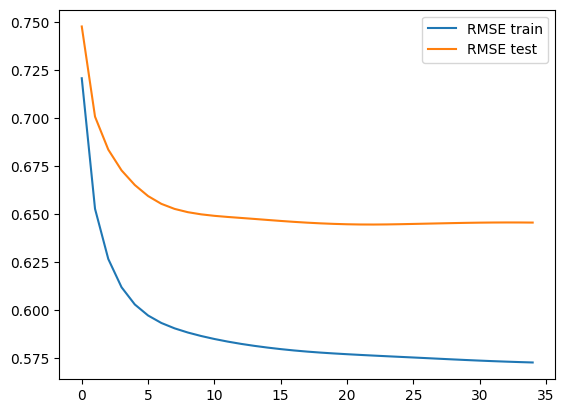

In [28]:
# plots of train's and test's rmse
plt.plot(rmse_train_2, label="RMSE train")
plt.plot(rmse_test_2, label = "RMSE test")
plt.legend()
plt.show()

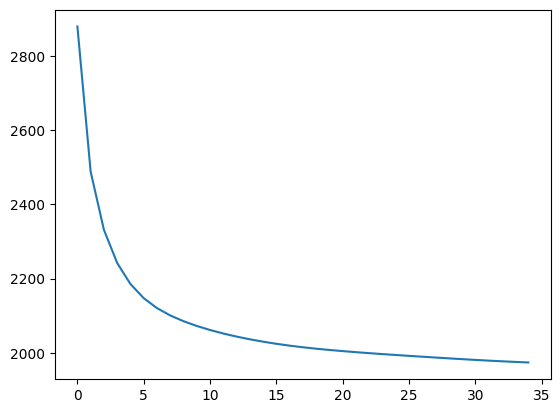

In [29]:
# Plot of loss function
plt.plot(loss_train_2)
plt.show()

# Pratical 4